# 🔎 RAG, hands-on – live demo
**Seminar 4 · Lewis et al. (2020), *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks***

Meet **BART** – a brilliant student who has read a huge amount, but takes every exam with a **closed book**.

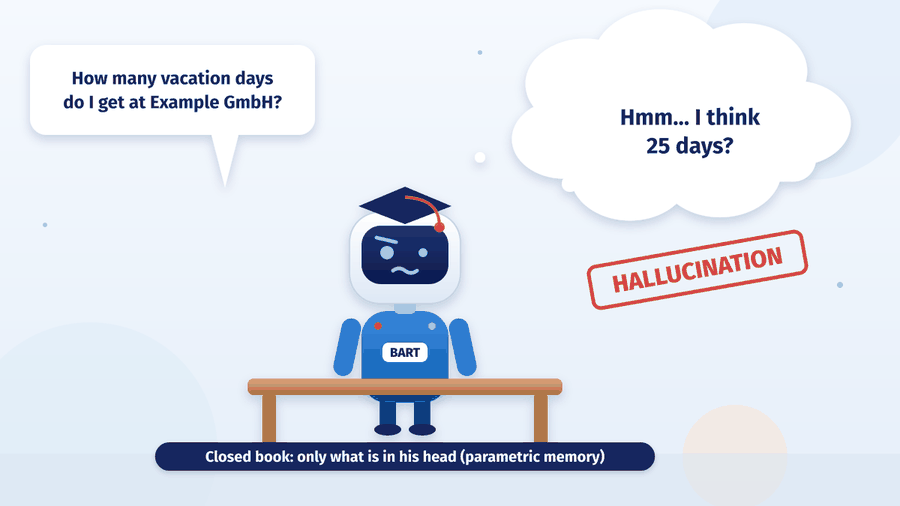

Ask him about a company he has never read about, and he still answers – fluently and confidently – and wrong.

<details><summary><b>🎤 What to say</b> (click)</summary>

"Let me introduce our main character. His name is BART – and that's not a joke, BART is the real name of the generator model in the paper:
BART-large, about 400 million parameters. Think of him as a very well-read student. Everything he knows sits *inside* his head –
in his parameters. That's what Nataliia called **parametric memory**.

Now we ask him something he could never have read: *How many vacation days do I get at Example GmbH?* – a company we made up.
A good student would say "I don't know". A language model doesn't – it writes the most *plausible-sounding* text. 25 days sounds plausible.
That confident guess is what we call a **hallucination**."

</details>

## 📚 The fix: give BART a library – and a librarian

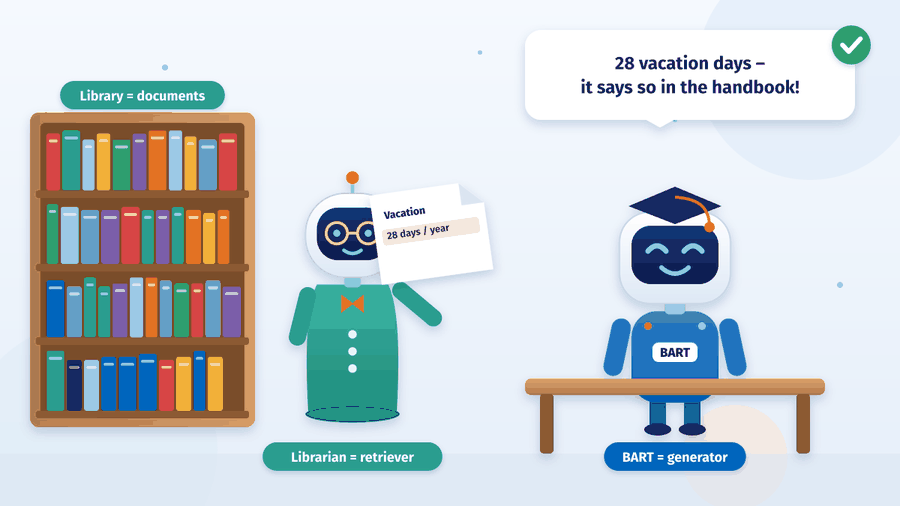

| Role | In the paper | In this demo |
|---|---|---|
| 📚 **Library** (non-parametric memory) | Wikipedia, Dec 2018: **21 million** passages × 100 words | the handbook of *Example GmbH* (fictional), 10 sections |
| 🤓 **Librarian** (retriever) | **DPR** – two BERT encoders | the same DPR models, downloaded |
| 🎓 **BART** (generator) | **BART-large**, fine-tuned | Flan-T5 (a similar encoder–decoder model) |

**Roadmap** – the same steps Turan showed, plus step 0:

| Step | What happens |
|---|---|
| **0 · Index** | Cut the handbook into chunks, write one "catalogue card" (768 numbers) per chunk – *once* |
| **1 · Encode** | Turn the question into 768 numbers too |
| **2 · Retrieve** | Compare the question with every card, keep the **top 3** |
| **3 · Augment** | Glue the question to **each** passage → one page per passage |
| **4 · Generate** | BART reads each page and writes a draft answer |
| **5 · Combine** | Weighted vote: relevance of the page × confidence of the draft |
| ⚡ **Shortcut** | How today's chatbots do it: all passages on one page |
| 🧪 **A · Swap a book** | New policy → new answer, no retraining |
| 🧪 **B · Sneak in a fake** | Does BART notice a wrong fact? |

> **Before the talk:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all` (first run downloads ~1.5 GB, 2–4 min).
> During the talk you only **scroll and explain**; re-run single cells only for audience questions.

<details><summary><b>🎤 What to say</b> (click)</summary>

"RAG's idea is simple: don't make the student memorise everything – give him a **library** and a **librarian**.
Three roles, and I'll use these words for the rest of the demo:
the **library** is the documents – in the paper that's all of Wikipedia, cut into 21 million passages of 100 words each; today it's a
small made-up company handbook. The **librarian** is the retriever – the model that finds the right pages. And **BART** stays the writer.

The key consequence: if the company changes a rule, we don't retrain BART. We just change a book in the library.

We'll go through exactly the steps Turan just explained – Encode, Retrieve, Augment, Generate, Combine – but with real models and real
numbers. I add one step at the beginning, step 0, because the library has to be prepared before anyone can ask a question."

</details>

In [ ]:
#@title ⚙️ Setup – run once before the talk (code hidden; double-click to see it)
!pip -q install transformers rank_bm25
import re, numpy as np, torch, matplotlib.pyplot as plt
from html import escape
from IPython.display import HTML, display
from transformers import (DPRQuestionEncoder, DPRQuestionEncoderTokenizer, DPRContextEncoder,
                          DPRContextEncoderTokenizer, AutoTokenizer, AutoModelForSeq2SeqLM)
device = "cuda" if torch.cuda.is_available() else "cpu"

# --- The librarian: DPR, the retriever family used in the paper ---
Q_NAME, C_NAME = "facebook/dpr-question_encoder-multiset-base", "facebook/dpr-ctx_encoder-multiset-base"
q_tok, q_enc = DPRQuestionEncoderTokenizer.from_pretrained(Q_NAME), DPRQuestionEncoder.from_pretrained(Q_NAME).to(device).eval()
c_tok, c_enc = DPRContextEncoderTokenizer.from_pretrained(C_NAME), DPRContextEncoder.from_pretrained(C_NAME).to(device).eval()
# --- BART's stand-in: a small open encoder-decoder model (the paper fine-tuned BART-large) ---
G_NAME = "google/flan-t5-large" if device == "cuda" else "google/flan-t5-base"
g_tok, g_model = AutoTokenizer.from_pretrained(G_NAME), AutoModelForSeq2SeqLM.from_pretrained(G_NAME).to(device).eval()

BLUE, ORANGE, GREY, GREEN, TEAL, RED = "#0065BD", "#E37222", "#999999", "#2E9E6B", "#2A9D8F", "#D64545"
INSTR = 'Answer the question using only the facts below. If the facts do not contain the answer, say "I don\'t know".'

def make_chunks(handbook):
    """Step 0a: cut every handbook section into one-sentence chunks (the paper: 100-word chunks)."""
    chunks = []
    for section, text in handbook.items():
        for sent in re.split(r"(?<=[.!?])\s+", text.strip()):
            if sent:
                chunks.append({"section": section, "text": sent})
    return chunks

@torch.no_grad()
def embed_chunks(chunks):
    """Step 0b: the document encoder writes one catalogue card (768 numbers) per chunk."""
    batch = c_tok([c["section"] for c in chunks], [c["text"] for c in chunks],
                  padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
    return c_enc(**batch).pooler_output.cpu().numpy()

@torch.no_grad()
def embed_question(question):
    """Step 1: the question encoder turns the question into 768 numbers."""
    return q_enc(**q_tok(question, return_tensors="pt").to(device)).pooler_output.cpu().numpy()[0]

def build_index(handbook, extra_chunks=()):
    chunks = make_chunks(handbook) + list(extra_chunks)
    return {"chunks": chunks, "vectors": embed_chunks(chunks)}

def retrieve(index, q_vec, k=3):
    """Step 2: score = dot product with every card; keep top-k; p(z|x) = softmax over the top-k (as in the paper)."""
    scores = index["vectors"] @ q_vec
    top = np.argsort(-scores)[:k]
    p = np.exp(scores[top] - scores[top].max()); p /= p.sum()
    return [dict(index["chunks"][i], score=float(scores[i]), p=float(pi), idx=int(i)) for i, pi in zip(top, p)], scores

def augment(question, hits):
    """Step 3: glue the question to the passage(s). One hit = the paper's way; several hits = today's shortcut."""
    facts = "\n".join(f"[{n+1}] {h['section']}: {h['text']}" for n, h in enumerate(hits))
    return f"{INSTR}\nFacts:\n{facts}\nQuestion: {question}\nAnswer:"

@torch.no_grad()
def generate(prompt):
    """Step 4: the generator writes an answer (greedy decoding, like the paper for QA)."""
    ids = g_tok(prompt, return_tensors="pt", truncation=True, max_length=512).to(device)
    out = g_model.generate(**ids, max_new_tokens=32)
    return g_tok.decode(out[0], skip_special_tokens=True).strip()

@torch.no_grad()
def answer_prob(prompt, answer):
    """p(answer | page): how confident the generator is in this exact answer, given this page."""
    ids = g_tok(prompt, return_tensors="pt", truncation=True, max_length=512).to(device)
    labels = g_tok(answer, return_tensors="pt").input_ids.to(device)
    return float(torch.exp(-g_model(**ids, labels=labels).loss * labels.shape[1]))

def combine(question, hits):
    """Steps 3-5, the paper's RAG-Sequence way: one page per passage, one draft per page, weighted vote."""
    pages = [augment(question, [h]) for h in hits]
    drafts = [generate(pg) for pg in pages]
    table = {}
    for cand in dict.fromkeys(drafts):
        conf = [answer_prob(pg, cand) for pg in pages]
        table[cand] = {"conf": conf, "total": sum(h["p"] * c for h, c in zip(hits, conf))}
    best = max(table, key=lambda a: table[a]["total"])
    return best, pages, drafts, table

def ask(index, question, k=3):
    """Today's shortcut: all top-k passages on one page, one answer."""
    hits, _ = retrieve(index, embed_question(question), k)
    return generate(augment(question, hits)), hits

# --- pretty output helpers ---
def card(title, body, color=BLUE):
    return (f"<div style='border-left:6px solid {color};background:#F4F6F9;padding:10px 14px;margin:6px 0;"
            f"border-radius:6px;font-family:Arial;font-size:15px;color:#111'><b style='color:{color}'>{title}</b><br>{body}</div>")

def show_hits(hits, scores):
    lo, hi = float(np.min(scores)), float(np.max(scores))
    rows = ""
    for n, h in enumerate(hits):
        w = 100 * (h["score"] - lo) / (hi - lo + 1e-9)
        rows += (f"<tr><td style='padding:6px'><b>[{n+1}]</b></td><td style='padding:6px'><b>{escape(h['section'])}</b><br>{escape(h['text'])}</td>"
                 f"<td style='padding:6px;width:240px'><div style='background:{BLUE};height:14px;width:{max(w,3):.0f}%;border-radius:3px'></div>"
                 f"<small>match score <b>{h['score']:.1f}</b> · weight p(z|x) = <b>{h['p']:.2f}</b></small></td></tr>")
    display(HTML(f"<table style='font-family:Arial;font-size:14px;border-collapse:collapse'>{rows}</table>"))

def show_pages(pages, drafts=None):
    html = "<div style='display:flex;gap:10px;flex-wrap:wrap'>"
    for n, pg in enumerate(pages):
        body = escape(pg).replace("\n", "<br>")
        if drafts: body += f"<hr><b style='color:{GREEN}'>BART's draft:</b> {escape(drafts[n])}"
        html += (f"<div style='flex:1;min-width:230px;background:white;border:1px solid #D5DEEA;border-top:6px solid {ORANGE};"
                 f"border-radius:6px;padding:10px;font-family:Arial;font-size:12.5px;color:#222'><b>Page {n+1}</b><br>{body}</div>")
    display(HTML(html + "</div>"))

def show_vote(hits, table, best):
    rows, mx = "", max(v["total"] for v in table.values()) + 1e-9
    for cand, v in sorted(table.items(), key=lambda kv: -kv[1]["total"]):
        terms = " + ".join(f"{h['p']:.2f}×{c:.2f}" for h, c in zip(hits, v["conf"]))
        col = GREEN if cand == best else GREY
        rows += (f"<tr><td style='padding:6px'><b>“{escape(cand)}”</b></td><td style='padding:6px;font-family:monospace'>{terms}</td>"
                 f"<td style='padding:6px;width:200px'><div style='background:{col};height:16px;width:{100*v['total']/mx:.0f}%;border-radius:3px'></div>"
                 f"<b>{v['total']:.3f}</b></td></tr>")
    display(HTML("<table style='font-family:Arial;font-size:14px;border-collapse:collapse'>"
                 "<tr><th align=left>draft answer</th><th align=left>Σ relevance × confidence (page 1 + 2 + 3)</th><th align=left>total</th></tr>"
                 f"{rows}</table>" + card("🏆 Final answer", escape(best), GREEN)))

def meaning_map(index, q_vec=None, hits=(), question=""):
    V = index["vectors"] / np.linalg.norm(index["vectors"], axis=1, keepdims=True)
    mu = V.mean(0); _, _, Wt = np.linalg.svd(V - mu, full_matrices=False)
    P = (V - mu) @ Wt[:2].T
    sections = list(dict.fromkeys(c["section"] for c in index["chunks"]))
    cmap = plt.get_cmap("tab20")
    plt.figure(figsize=(9, 5.5))
    for si, sec in enumerate(sections):
        ids = [i for i, c in enumerate(index["chunks"]) if c["section"] == sec]
        plt.scatter(P[ids, 0], P[ids, 1], s=90, color=cmap(si % 20), label=sec, edgecolor="white")
    if q_vec is not None:
        q = q_vec / np.linalg.norm(q_vec); qp = (q - mu) @ Wt[:2].T
        for h in hits:
            plt.plot([qp[0], P[h["idx"], 0]], [qp[1], P[h["idx"], 1]], color=ORANGE, lw=1.5, ls="--")
        plt.scatter(*qp, marker="*", s=600, color=ORANGE, edgecolor="black", zorder=5, label="your question")
    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9, frameon=False)
    plt.title("Meaning map: each dot is one catalogue card (768 numbers squeezed into 2D)", fontsize=12)
    plt.xticks([]); plt.yticks([]); plt.tight_layout(); plt.show()

print(f"✅ Ready – librarian: DPR, writer: {G_NAME}, running on {device}")

## 📄 Our library: the handbook of *Example GmbH* (fictional)
<details><summary><b>🎤 What to say</b> (click)</summary>

"This is our whole library – ten short sections of a company handbook we invented, so no model can possibly have seen it in training.
Wikipedia has 21 million passages; we have about twenty sentences. The mechanism is exactly the same – only the scale differs."

</details>

In [ ]:
HANDBOOK = {
    "Vacation": "Every full-time employee receives 28 vacation days per year. Unused vacation can be carried over until 31 March of the following year.",
    "Home office": "Employees may work from home up to three days per week. Team meetings on Tuesday must be attended in person.",
    "Travel": "For business trips, employees may book hotels up to 120 euros per night. Trains are booked in second class, and flights are only allowed for distances over 600 kilometres.",
    "Expenses": "Receipts must be uploaded in the expense app within 30 days after the trip. Reimbursement is paid with the next monthly salary.",
    "IT helpdesk": "Forgotten passwords are reset by the IT helpdesk at phone extension 4242. Laptops are replaced every three years.",
    "Cafeteria": "The cafeteria is open from 11:30 to 14:00. A lunch menu costs 4.50 euros for employees.",
    "Parking": "Bicycle parking is free. A car parking space costs 30 euros per month.",
    "Onboarding": "Every new employee gets an onboarding buddy for the first three months. The buddy answers questions about tools, people and processes.",
    "Sick leave": "If you are sick, inform your manager before 9:00. From the fourth day of illness, a doctor's certificate is required.",
    "Training budget": "Each employee has a training budget of 1,500 euros per year for courses, conferences and books.",
}
print(len(HANDBOOK), "sections,", sum(len(t.split()) for t in HANDBOOK.values()), "words")

---
## 0 · Index – the librarian writes one catalogue card per chunk (once!)
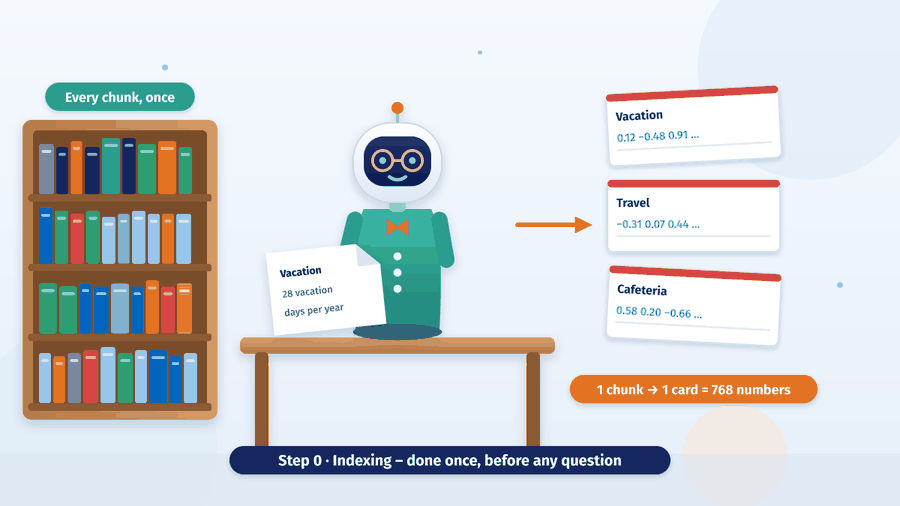

<details><summary><b>🎤 What to say</b> (click)</summary>

"Before anybody asks anything, the librarian prepares the library. Two things happen.

**First, chunking.** We cut the handbook into small pieces – here one sentence each; the paper used 100-word pieces of Wikipedia.
Why cut at all? Because the librarian should hand BART exactly the paragraph he needs, not the whole book.

**Second, the catalogue cards.** For every chunk, the *document encoder* – a BERT model – reads it and writes down **768 numbers**.
That list of numbers is the chunk's catalogue card. Why 768? It's simply the width of BERT-base: inside, BERT has 12 attention heads,
each looking at the text with 64 numbers, and 12 × 64 = 768. More numbers = more room to describe meaning; 768 was the standard size in 2020.

Important: this is done **once**. In the paper, writing 21 million cards took a long time and produced an index of about 100 GB –
but after that, every question can reuse it. And this document encoder is **frozen** during RAG training, exactly as Turan said –
otherwise all 21 million cards would have to be rewritten after every training step.

Below you see one card, and then a 'meaning map': all our cards squeezed from 768 dimensions down to 2 so we can look at them."

</details>

In [ ]:
index = build_index(HANDBOOK)
print(f"{len(index['chunks'])} chunks → each became a catalogue card of {index['vectors'].shape[1]} numbers\n")
c = index["chunks"][0]
print(f"Example chunk:  [{c['section']}] {c['text']}")
print("Its card:       [" + ", ".join(f"{v:.2f}" for v in index["vectors"][0][:6]) + ", … ]  (768 numbers)")
meaning_map(index)

**What to notice:** chunks about similar topics land close together – e.g. *Travel* near *Expenses*.
Nobody told the model these topics are related; the numbers capture **meaning**, not exact words.

---
## 1 · Encode – the question becomes 768 numbers, too
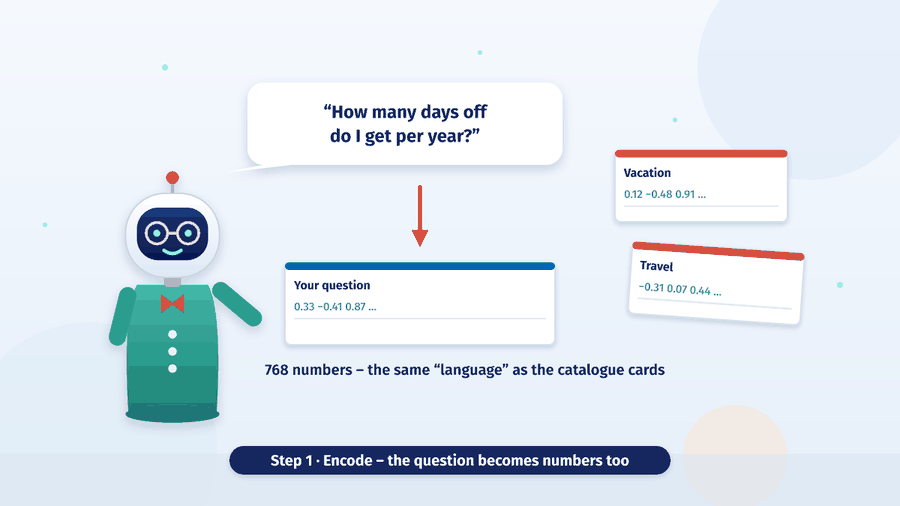

<details><summary><b>🎤 What to say</b> (click)</summary>

"Now a user asks: *How many days off do I get per year?*

The librarian can't compare words with numbers, so the question gets its own card. A second BERT – the **question encoder** –
turns it into 768 numbers in the **same 'language'** as the catalogue cards.

Why two encoders and not one? Questions and answers look different: a question is short and has a question word; a passage is a statement.
DPR trained one encoder for each side, so that a question and *the passage that answers it* end up with similar numbers.
And this question encoder is the part RAG keeps training – that's how the librarian 'learns what to look up' in the paper."

*(Optional, ask the audience: "Give me a question!" – type it into the field and re-run steps 1–5.)*

</details>

In [ ]:
question = "How many days off do I get per year?"   #@param {type:"string"}
q_vec = embed_question(question)
print("Question:", question)
print("Its card: [" + ", ".join(f"{v:.2f}" for v in q_vec[:6]) + ", … ]   (768 numbers)")

---
## 2 · Retrieve – compare numbers, keep the top 3
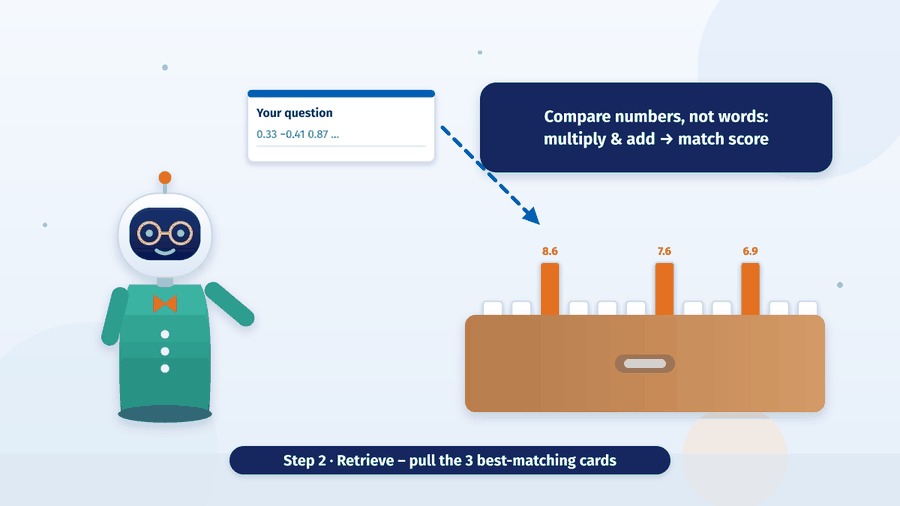

<details><summary><b>🎤 What to say</b> (click)</summary>

"Now the librarian compares the question card with every catalogue card. The comparison is the **dot product**:
multiply the two lists number by number – first with first, second with second, all 768 – and add everything up.
If both cards are big in the same places, the sum is big → good match. That's the match score.

Then we keep only the **top 3**. Why not all? Because BART can only read a few pages – and every extra page costs time.
Why not just 1? Because the best-scoring card can be wrong; a few cards are a safety net. The paper used 5 or 10 during training
and up to 50 at test time; for our tiny library, 3 is plenty.

The scores are turned into **weights** with a softmax – that's Turan's p(z|x). They add up to 1 and say how much we trust each page.
Keep those weights in mind, we need them in step 5.

**Why is this so fast?** Three reasons: the cards were written beforehand; comparing is just multiplication and addition, which
a GPU does billions of times per second; and in the paper the FAISS index works like signposts in the library – it walks towards the
right shelves instead of checking all 21 million cards.

Look at the map: the orange star is our question, the dashed lines go to the three cards the librarian pulled.
And notice: the question says **'days off'**, the handbook says **'vacation days'** – no shared word, still found. Meaning, not keywords."

</details>

In [ ]:
hits, all_scores = retrieve(index, q_vec, k=3)
show_hits(hits, all_scores)
meaning_map(index, q_vec, hits, question)

*The 2D map is only an approximation of 768 dimensions – the scores in the table are the real measure.*

---
## 3 · Augment – glue the question to **each** passage (the paper's way)
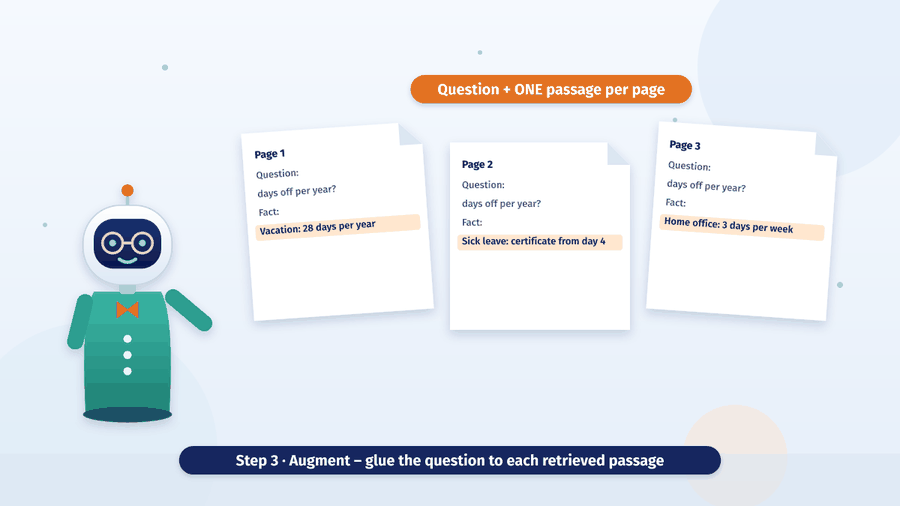

<details><summary><b>🎤 What to say</b> (click)</summary>

"'Augment' just means: **enrich the input**. BART doesn't only get the question any more – he gets the question *plus* a passage.
The paper literally says 'we simply concatenate' – glue the two texts together.

Detail that most people miss: in the paper, BART does **not** get one page with all passages. He gets **one page per passage** –
question + passage 1, question + passage 2, question + passage 3. Three separate pages.
Here are the three pages exactly as the model receives them."

</details>

In [ ]:
pages = [augment(question, [h]) for h in hits]
show_pages(pages)

---
## 4 · Generate – BART writes one draft per page
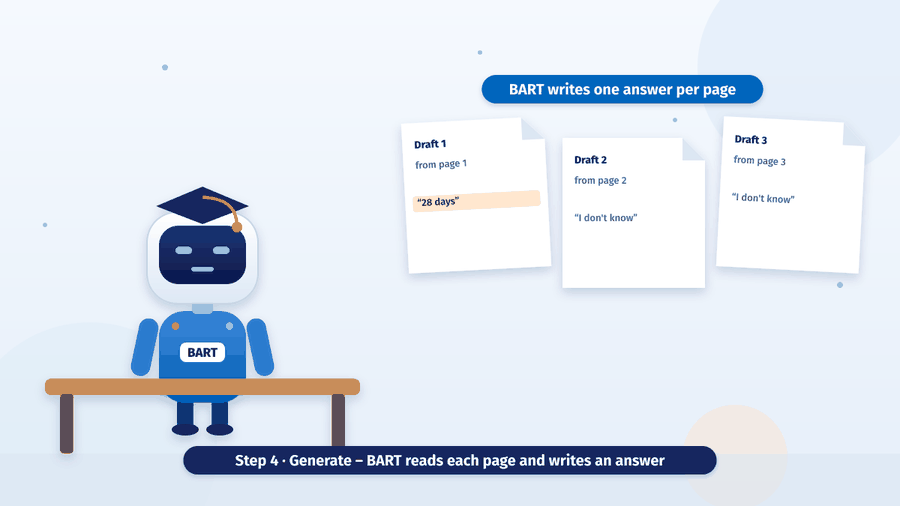

<details><summary><b>🎤 What to say</b> (click)</summary>

"Now BART reads each page separately and writes a draft answer for each one.
On the page with the vacation passage he should write '28 days'. On pages about something else, the honest draft is 'I don't know'.

So now we have three drafts – which one is the answer? That's step 5."

</details>

In [ ]:
best, pages, drafts, table = combine(question, hits)
show_pages(pages, drafts)

---
## 5 · Combine – a weighted vote
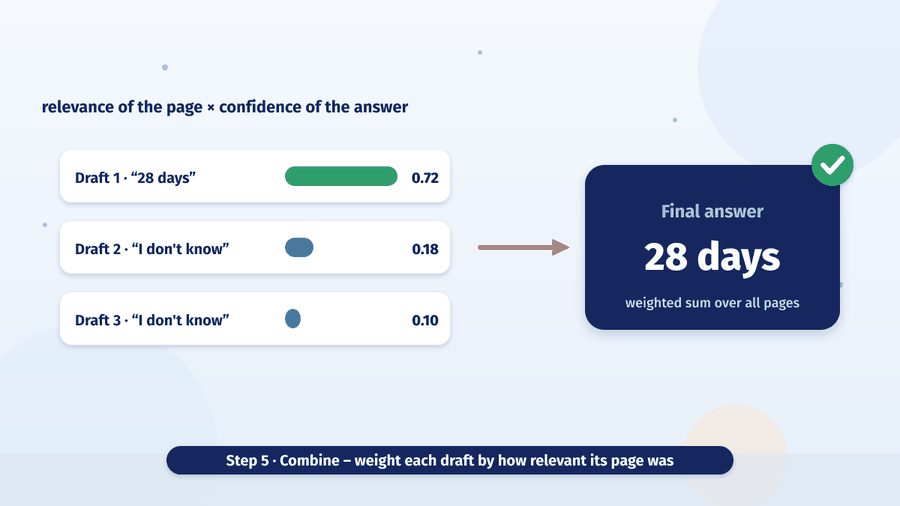

<details><summary><b>🎤 What to say</b> (click)</summary>

"Every draft gets a vote, and the vote is weighted by two things:
**how relevant the page was** – the librarian's weight from step 2 – times **how confident BART is in that answer given that page**.
Add this up over all pages, and that's the formula Turan showed: p(answer | question) = Σ p(page | question) · p(answer | question, page).
This is the paper's RAG-Sequence model.

Read the table: each row is one candidate answer; the middle column is the sum, page by page. The highest total wins.
Nice side effect: a wrong page with a low weight can hardly change the result."

</details>

In [ ]:
show_hits(hits, all_scores)
show_vote(hits, table, best)

---
## ⚡ Today's shortcut: everything on one page – and the comparison without RAG
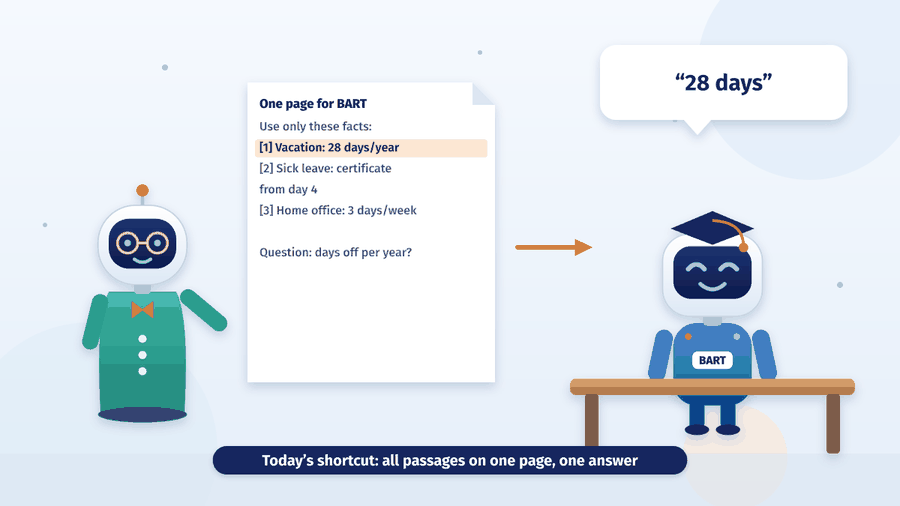

<details><summary><b>🎤 What to say</b> (click)</summary>

"What ChatGPT-style systems do today is simpler: put all top passages on **one** page, ask for **one** answer.
Modern models can read long inputs, so this works well – the paper's per-page approach came from 2020, when inputs were short.

And now the moment of truth: same model, same question – **with** the library and **without** it."

</details>

In [ ]:
one_page = augment(question, hits)
display(HTML(card("One page for BART (exactly what the model receives)", escape(one_page).replace("\n", "<br>"), GREY)))
with_rag = generate(one_page)
without_rag = generate(f"Answer the question: {question} (at the company Example GmbH)")
display(HTML(card("✅ With RAG", f"{escape(with_rag)}<br><small>Source: [1] {escape(hits[0]['section'])}</small>", GREEN)
             + card("❌ Without RAG – closed book", escape(without_rag), RED)))

**What to notice:** with RAG the answer comes **with a source** – you can check it. Without RAG the model guesses.

---
## 🧪 A · Swap a book – update the knowledge, no retraining
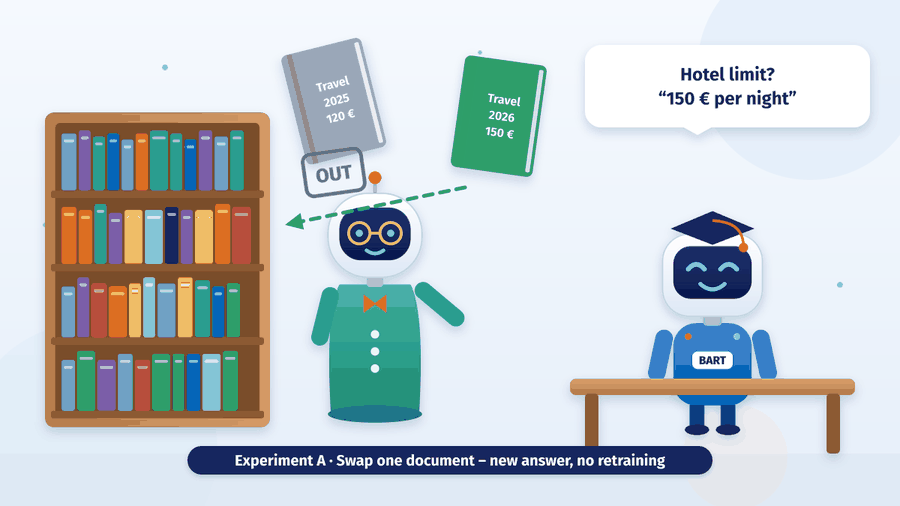

<details><summary><b>🎤 What to say</b> (click)</summary>

"Experiment one. Example GmbH updates its travel policy for 2026: hotels up to **150 euros** instead of 120.
With a normal language model, you would have to retrain it – weeks of GPU time. With RAG we take the old book out,
put the new one in, write one new catalogue card – done.

This is the paper's **hot-swap** experiment: they swapped the 2018 Wikipedia index for a 2016 one and asked about world leaders.
With the matching index, RAG got about 70% right; with the mismatched index, only around 4–12%. Knowledge lives in the library."

</details>

In [ ]:
HANDBOOK_2026 = dict(HANDBOOK, Travel=HANDBOOK["Travel"].replace("120 euros", "150 euros"))
q = "How much can I spend on a hotel per night?"
old_answer, _ = ask(index, q)
new_answer, _ = ask(build_index(HANDBOOK_2026), q)
display(HTML(f"<p style='font-family:Arial;font-size:15px'><b>Question:</b> {q}</p>"
             + card("📘 Handbook 2025", escape(old_answer), GREY)
             + card("📗 Handbook 2026 – only the document changed, no training", escape(new_answer), GREEN)))

---
## 🧪 B · Sneak in a fake – does BART notice?
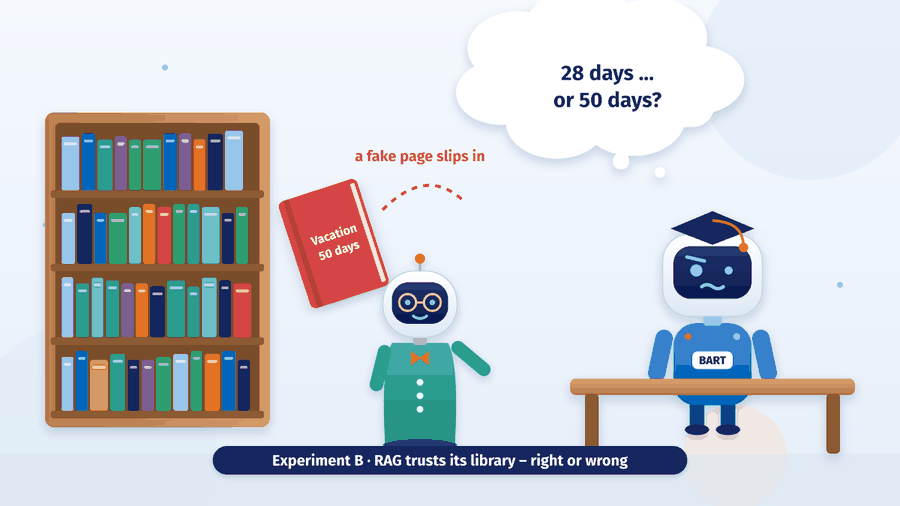

<details><summary><b>🎤 What to say</b> (click)</summary>

"Experiment two – the dark side. We sneak **one false sentence** into the library: '50 vacation days per year'.
Let's ask again.

*(Run.)* Look at the table first: the librarian pulls the fake page right to the top – it matches the question very well.
→ **If the answer says 50:** BART believed it. → **If it says 28:** he got lucky this time – but the fake page is sitting in his reading pile,
and on another run or another question it can win.
Either way, RAG has no built-in fact checker: it is **only as good as its library**. That's why in companies, the real work is curating the documents –
and why showing the source matters: a human can check where '50 days' came from."

</details>

In [ ]:
WRONG = {"section": "Vacation (update)", "text": "From now on, every employee receives 50 vacation days per year."}
q = "How many vacation days do I get per year?"
answer, hits_b = ask(build_index(HANDBOOK, [WRONG]), q)
show_hits(hits_b, np.array([h["score"] for h in hits_b]))
display(HTML(card("Answer", escape(answer), RED)))

**Question to the audience:** two pages contradict each other (28 vs. 50). Who should decide which one is right – the model, or the people who maintain the library?

---
## 🙋 Your turn
Type any question from the audience – try one the handbook **cannot** answer (the model should say "I don't know").
<details><summary><b>🎤 What to say</b> (click)</summary>

"Who wants to try? Give me any question about working at Example GmbH – or one the handbook can't answer."
Good test questions: *Can I work from home on Fridays?* · *Who resets my password?* · *Is there a gym?* (not in the handbook)

</details>

In [ ]:
audience_question = "Can I work from home on Fridays?"   #@param {type:"string"}
answer, hits_t = ask(index, audience_question)
show_hits(hits_t, np.array([h["score"] for h in hits_t]))
display(HTML(card("Answer", escape(answer), BLUE)))

---
## 📎 Extra (only for questions): keyword search vs. meaning search
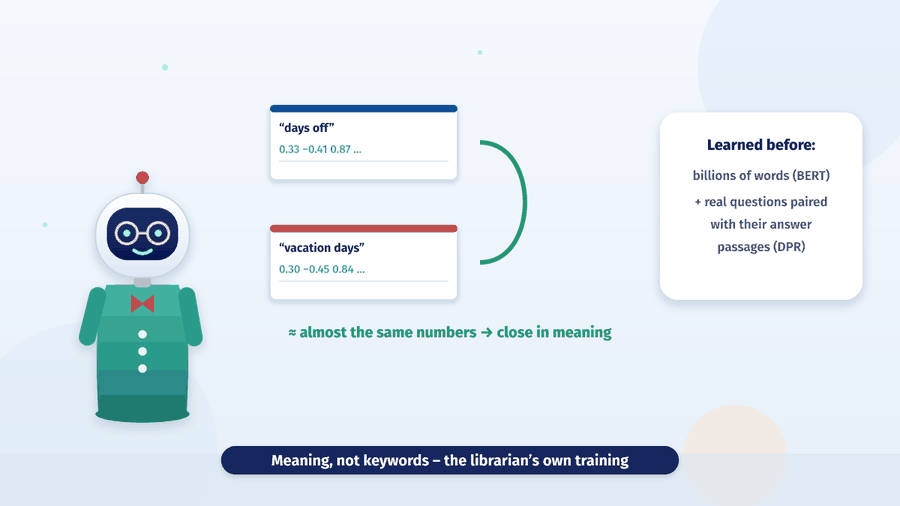

BM25 is classic keyword matching – the paper's baseline retriever. DPR compares meaning.
<details><summary><b>🎤 What to say</b> (click)</summary>

"Someone might ask: why not just search for keywords, like Ctrl+F? Here: 'canteen' and 'meal' don't appear in the handbook – it says
'cafeteria' and 'lunch menu'. Keyword search has nothing to hold on to; the librarian still finds the right card.
Fun fact from the paper though: for FEVER, a fact-checking dataset, keyword search was actually better – entity names matter a lot there."

</details>

In [ ]:
from rank_bm25 import BM25Okapi
tok = lambda s: [w.strip(".,?!'\"").lower() for w in s.split()]
bm25 = BM25Okapi([tok(c["section"] + " " + c["text"]) for c in index["chunks"]])
q = "How much is a meal at the canteen?"
best_kw = index["chunks"][int(np.argmax(bm25.get_scores(tok(q))))]
best_dpr, _ = retrieve(index, embed_question(q), k=1)
print("Question:", q)
print("Keyword search (BM25) picks:", f"[{best_kw['section']}] {best_kw['text']}")
print("Meaning search (DPR) picks: ", f"[{best_dpr[0]['section']}] {best_dpr[0]['text']}")

---
*Honest note:* the paper **trains** the question encoder and BART together on ~79k question–answer pairs (Natural Questions), starting from a
DPR retriever that was already trained on questions + answer passages. Here nothing is trained: the librarian is the pre-trained DPR from the
paper's authors, the writer is an off-the-shelf Flan-T5. The demo shows the **mechanism**, not the paper's numbers.